<a href="https://colab.research.google.com/github/AslanZeinalov/Bike-store-analysis/blob/main/bike_store_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚴 Аналитика и исследование продаж сети веломагазинов

В данном проекте проводится комплексный анализ базы данных розничной сети веломагазинов.

**Основные цели исследования:**
1. Анализ динамики выручки во времени (по годам, месяцам и дням недели).
2. Анализ логистических цепочек и оценка упущенной прибыли из-за дефицита товаров.
3. Определение ключевых драйверов продаж (хиты и аутсайдеры среди продуктов).
4. Сегментация клиентской базы для разработки программ лояльности.

#Аналитика веломагазина

In [ ]:
import kagglehub

path = kagglehub.dataset_download("dillonmyrick/bike-store-sample-database")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'bike-store-sample-database' dataset.
Path to dataset files: /kaggle/input/bike-store-sample-database


### Шаг 1. Импорт библиотек и загрузка данных

In [ ]:
!ls /root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3

brands.csv	customers.csv	 orders.csv    staffs.csv  stores.csv
categories.csv	order_items.csv  products.csv  stocks.csv


In [ ]:
import pandas as pd
import sqlite3

brands = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/brands.csv')
customers = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/customers.csv')
orders = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/orders.csv')
staffs = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/staffs.csv')
stores = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/stores.csv')
categories = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/categories.csv')
order_items = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/order_items.csv')
products = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/products.csv')
stocks = pd.read_csv('/root/.cache/kagglehub/datasets/dillonmyrick/bike-store-sample-database/versions/3/stocks.csv')




In [ ]:
connection = sqlite3.connect('bike_store.db')

In [ ]:
brands.to_sql('brands', connection, if_exists='replace', index=False)
customers.to_sql('customers', connection, if_exists='replace', index=False)
orders.to_sql('orders', connection, if_exists='replace', index=False)
staffs.to_sql('staffs', connection, if_exists='replace', index=False)
stores.to_sql('stores', connection, if_exists='replace', index=False)
categories.to_sql('categories', connection, if_exists='replace', index=False)
order_items.to_sql('order_items', connection, if_exists='replace', index=False)
products.to_sql('products', connection, if_exists='replace', index=False)
stocks.to_sql('stocks', connection, if_exists='replace', index=False);


### Шаг 2. Обзор структуры таблиц базы данных

In [ ]:
tables = [brands, customers, orders, staffs, stores, categories, order_items, products, stocks]

In [ ]:
for table in tables:
  print(table.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   brand_id    9 non-null      int64 
 1   brand_name  9 non-null      object
dtypes: int64(1), object(1)
memory usage: 276.0+ bytes
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1445 entries, 0 to 1444
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  1445 non-null   int64 
 1   first_name   1445 non-null   object
 2   last_name    1445 non-null   object
 3   phone        178 non-null    object
 4   email        1445 non-null   object
 5   street       1445 non-null   object
 6   city         1445 non-null   object
 7   state        1445 non-null   object
 8   zip_code     1445 non-null   int64 
dtypes: int64(2), object(7)
memory usage: 101.7+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1615 entries, 0 

Проанализируем распределение продаж по временным интервалам

## 📈 Раздел 1. Временной анализ продаж и выручки

In [ ]:
qwery = '''
SELECT *
FROM orders O
JOIN order_items oi USING(order_id)
'''

orders_df = pd.read_sql(qwery, connection)
orders_df.head(10)

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id,item_id,product_id,quantity,list_price,discount
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,1,20,1,599.99,0.20
1,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2,8,2,1799.99,0.07
2,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,3,10,2,1549.00,0.05
3,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,4,16,2,599.99,0.05
4,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,5,4,1,2899.99,0.20
5,2,1212,4,2016-01-01,2016-01-04,2016-01-03,2,6,1,20,1,599.99,0.07
6,2,1212,4,2016-01-01,2016-01-04,2016-01-03,2,6,2,16,2,599.99,0.05
7,3,523,4,2016-01-02,2016-01-05,2016-01-03,2,7,1,3,1,999.99,0.05
8,3,523,4,2016-01-02,2016-01-05,2016-01-03,2,7,2,20,1,599.99,0.05
9,4,175,4,2016-01-03,2016-01-04,2016-01-05,1,3,1,2,2,749.99,0.10


Создадим колонку с ценой с учетом скидки

In [ ]:
orders_df['discount_price'] = orders_df['list_price'] - orders_df['list_price'] * orders_df['discount']
orders_df.head(1)

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id,item_id,product_id,quantity,list_price,discount,discount_price
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,1,20,1,599.99,0.2,479.992


Проверим наши  данные на наличие пропусков и выбросов:

In [ ]:
orders_df.isna().sum()

,0
order_id,0
customer_id,0
order_status,0
order_date,0
required_date,0
shipped_date,508
store_id,0
staff_id,0
item_id,0
product_id,0


В колонке shipped_date много пропусков. Нужно будет разобраться по

In [ ]:
orders_df.describe()

,order_id,customer_id,order_status,store_id,staff_id,item_id,product_id,quantity,list_price,discount,discount_price
count,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000,4722.000000
mean,821.265354,659.057603,3.772342,1.897289,5.871665,2.262601,59.366158,1.498941,1212.707872,0.105373,1086.009722
std,465.152168,444.190561,0.702262,0.559372,1.905089,1.199129,67.312708,0.500052,1352.798257,0.058119,1221.462277
min,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,89.990000,0.050000,71.992000
25%,423.250000,238.250000,4.000000,2.000000,6.000000,1.000000,14.000000,1.000000,429.000000,0.050000,375.291000
50%,828.500000,646.500000,4.000000,2.000000,6.000000,2.000000,28.000000,1.000000,599.990000,0.085000,522.490500
75%,1226.000000,1052.000000,4.000000,2.000000,7.000000,3.000000,84.000000,2.000000,1549.000000,0.200000,1394.100000
max,1615.000000,1445.000000,4.000000,3.000000,9.000000,5.000000,315.000000,2.000000,11999.990000,0.200000,11159.990700


Сгруппируем нашу таблицу по датам и найдем сумму покупок

In [ ]:
orders_df['order_date'] = pd.to_datetime(orders_df['order_date'])
orders_df['order_date'].info()

<class 'pandas.core.series.Series'>
RangeIndex: 4722 entries, 0 to 4721
Series name: order_date
Non-Null Count  Dtype         
--------------  -----         
4722 non-null   datetime64[ns]
dtypes: datetime64[ns](1)
memory usage: 37.0 KB


In [ ]:
revenue_by_date = orders_df.groupby('order_date', as_index=False).agg(revenue=('discount_price', 'sum'))
revenue_by_date.head(10)

,order_date,revenue
0,2016-01-01,7643.4964
1,2016-01-02,1519.9810
2,2016-01-03,3103.5017
3,2016-01-04,7793.4958
4,2016-01-05,6275.9555
5,2016-01-06,4206.9315
6,2016-01-08,1760.5225
7,2016-01-09,3289.1141
8,2016-01-12,5811.5286
9,2016-01-14,15702.5777


Добавим столбы с годом, месяцем, днем недели

In [ ]:
revenue_by_date['order_date'] = pd.to_datetime(revenue_by_date['order_date'])
revenue_by_date['year'] = revenue_by_date['order_date'].dt.year
revenue_by_date['mounth'] = revenue_by_date['order_date'].dt.month
revenue_by_date['weekday'] = revenue_by_date['order_date'].dt.weekday
revenue_by_date.head(1)

,order_date,revenue,year,mounth,weekday
0,2016-01-01,7643.4964,2016,1,4


In [ ]:
year_revenue = revenue_by_date.groupby('year', as_index=False)['revenue'].sum()
mounth_revenue = revenue_by_date.groupby('mounth', as_index=False)['revenue'].sum()
weekday_revenue = revenue_by_date.groupby('weekday', as_index=False)['revenue'].sum()

periods = [year_revenue, mounth_revenue, weekday_revenue]

<BarContainer object of 3 artists>

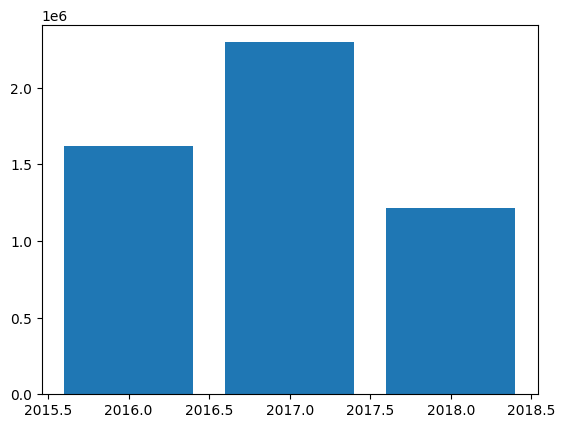

In [ ]:
import matplotlib.pyplot as plt
plt.bar(year_revenue['year'], year_revenue['revenue'])

<BarContainer object of 12 artists>

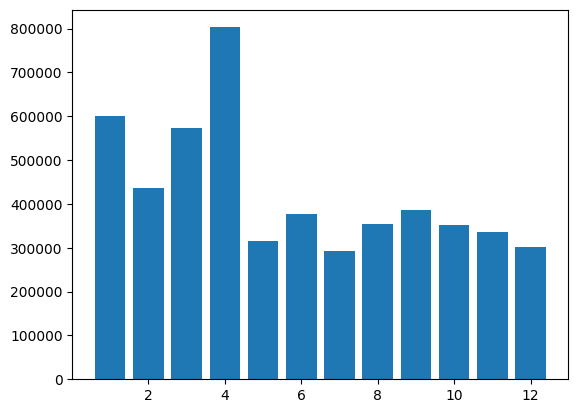

In [ ]:
plt.bar(mounth_revenue['mounth'], mounth_revenue['revenue'])

<BarContainer object of 7 artists>

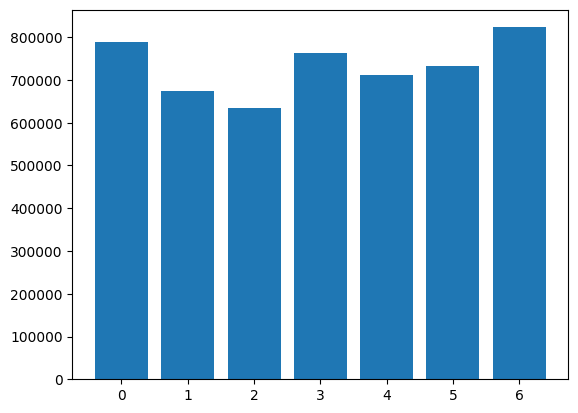

In [ ]:
plt.bar(weekday_revenue['weekday'], weekday_revenue['revenue'])

## 📦 Раздел 2. Анализ цепочки поставок и упущенной выручки

Проанализируем пропуски в колонке shipped_date

Создадим новую таблицу в которую выгрузим строки с пропущенными значениями в колонке shipped_date. Отсутствующие значения указывают на то что заказ был сделан, но не отправлен, надо выяснить почему.

In [ ]:
missing_shipped_date = orders_df[orders_df['shipped_date'].isna()]
missing_shipped_date.info()

<class 'pandas.core.frame.DataFrame'>
Index: 508 entries, 201 to 4721
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        508 non-null    int64         
 1   customer_id     508 non-null    int64         
 2   order_status    508 non-null    int64         
 3   order_date      508 non-null    datetime64[ns]
 4   required_date   508 non-null    object        
 5   shipped_date    0 non-null      object        
 6   store_id        508 non-null    int64         
 7   staff_id        508 non-null    int64         
 8   item_id         508 non-null    int64         
 9   product_id      508 non-null    int64         
 10  quantity        508 non-null    int64         
 11  list_price      508 non-null    float64       
 12  discount        508 non-null    float64       
 13  discount_price  508 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(8), object(2)
memory

Проверим каких товаров не было в наличии:

In [ ]:
missing_ids = missing_shipped_date['product_id'].value_counts().reset_index()
missing_ids = missing_ids.sort_values('count', ascending=False)
missing_ids

,product_id,count
0,15,7
1,20,7
2,24,6
3,36,6
6,17,5
...,...,...
239,76,1
256,175,1
257,228,1
258,289,1


Проверим распределение по датам:

In [ ]:
missing_shipped_date_by_dates = missing_shipped_date.groupby('order_date').agg(count=('item_id', 'count')).sort_values('count', ascending=False)
missing_shipped_date_by_dates.head(5)

,count
order_date,
2018-04-06,27
2018-04-12,25
2018-04-17,24
2018-04-23,22
2018-04-27,21


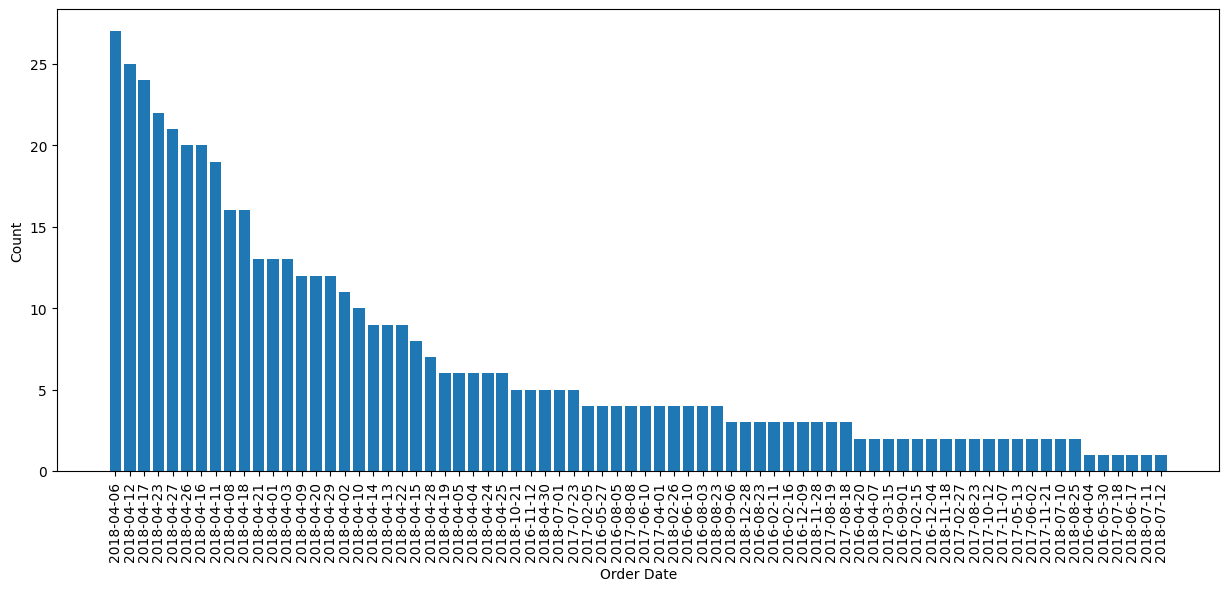

In [ ]:
plt.figure(figsize=(15, 6))
plt.bar(missing_shipped_date_by_dates.index.astype(str), missing_shipped_date_by_dates['count'])
plt.xticks(rotation=90)
plt.xlabel('Order Date')
plt.ylabel('Count')
plt.show()

Можно сделать вывод, что больше всего нехватало товара в апреле - месяц на который приходится пик продаж.

Проанализируем каких позиций нехватало в апреле и в каких колличествах

In [ ]:
missing_shipped_date['month'] = missing_shipped_date['order_date'].dt.month
april = missing_shipped_date[missing_shipped_date['month'] == 4]
missing_items_april = april.groupby('product_id', as_index=False).agg(count=('item_id', 'count')).sort_values('count', ascending=False)
missing_items_april

/tmp/ipykernel_75493/3707109051.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  missing_shipped_date['month'] = missing_shipped_date['order_date'].dt.month


,product_id,count
26,37,5
29,41,4
36,49,4
69,95,4
67,92,4
...,...,...
233,309,1
235,311,1
236,312,1
238,314,1


Данную таблицу нужно использовать для планирования поставок в апреле

Рассчитаем упущенную прибыль:

In [ ]:
print(f"Упущенная выручка из за нехватки товаров на складе сезон пика продаж: {april['discount_price'].sum():.0f}")


Упущенная выручка из за нехватки товаров на складе сезон пика продаж: 546295


Посмотрим продажи по категориям

## 🏷️ Раздел 3. Товарная аналитика и структура категорий

In [ ]:
orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4722 entries, 0 to 4721
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        4722 non-null   int64         
 1   customer_id     4722 non-null   int64         
 2   order_status    4722 non-null   int64         
 3   order_date      4722 non-null   datetime64[ns]
 4   required_date   4722 non-null   object        
 5   shipped_date    4214 non-null   object        
 6   store_id        4722 non-null   int64         
 7   staff_id        4722 non-null   int64         
 8   item_id         4722 non-null   int64         
 9   product_id      4722 non-null   int64         
 10  quantity        4722 non-null   int64         
 11  list_price      4722 non-null   float64       
 12  discount        4722 non-null   float64       
 13  discount_price  4722 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(8), object(2)
me

In [ ]:
qwery = '''
SELECT
    order_id,
    customer_id,
    order_status,
    order_date,
    required_date,
    shipped_date,
    store_id,
    staff_id,
    item_id,
    product_id,
    quantity,
    oi.list_price,
    discount,
    product_name,
    brand_id,
    category_id,
    model_year,
    category_name
FROM orders O
JOIN order_items oi USING(order_id)
JOIN products p USING(product_id)
JOIN categories c USING(category_id)
'''

orders_df_with_categories = pd.read_sql(qwery, connection)
orders_df_with_categories

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id,item_id,product_id,quantity,list_price,discount,product_name,brand_id,category_id,model_year,category_name
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,1,20,1,599.99,0.20,Electra Townie Original 7D EQ - Women's - 2016,1,3,2016,Cruisers Bicycles
1,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2,8,2,1799.99,0.07,Trek Remedy 29 Carbon Frameset - 2016,9,6,2016,Mountain Bikes
2,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,3,10,2,1549.00,0.05,Surly Straggler - 2016,8,4,2016,Cyclocross Bicycles
3,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,4,16,2,599.99,0.05,Electra Townie Original 7D EQ - 2016,1,3,2016,Cruisers Bicycles
4,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,5,4,1,2899.99,0.20,Trek Fuel EX 8 29 - 2016,9,6,2016,Mountain Bikes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4717,1614,135,3,2018-11-28,2018-11-28,None,3,8,2,159,2,2299.99,0.07,Trek Emonda ALR 6 - 2018,9,7,2018,Road Bikes
4718,1614,135,3,2018-11-28,2018-11-28,None,3,8,3,213,2,269.99,0.20,Electra Cruiser 1 - 2016/2017/2018,1,3,2018,Cruisers Bicycles
4719,1615,136,3,2018-12-28,2018-12-28,None,3,8,1,197,2,2299.99,0.20,Trek Verve+ Lowstep - 2018,9,5,2018,Electric Bikes
4720,1615,136,3,2018-12-28,2018-12-28,None,3,8,2,214,1,899.99,0.07,Electra Tiger Shark 3i - 2018,1,3,2018,Cruisers Bicycles


In [ ]:
orders_df_with_categories['discount_price'] = orders_df_with_categories['list_price'] - orders_df_with_categories['list_price'] * orders_df_with_categories['discount']
revenue_by_category = orders_df_with_categories.groupby('category_name', as_index=False).agg(revenue=('discount_price', 'sum')).sort_values('revenue', ascending=False)
revenue_by_category.head(10)

,category_name,revenue
5,Mountain Bikes,1.828526e+06
6,Road Bikes,1.107829e+06
2,Cruisers Bicycles,6.675362e+05
4,Electric Bikes,6.082721e+05
3,Cyclocross Bicycles,4.612127e+05
1,Comfort Bicycles,2.599501e+05
0,Children Bicycles,1.948113e+05


Text(0.5, 1.0, 'Выручка по категориям')

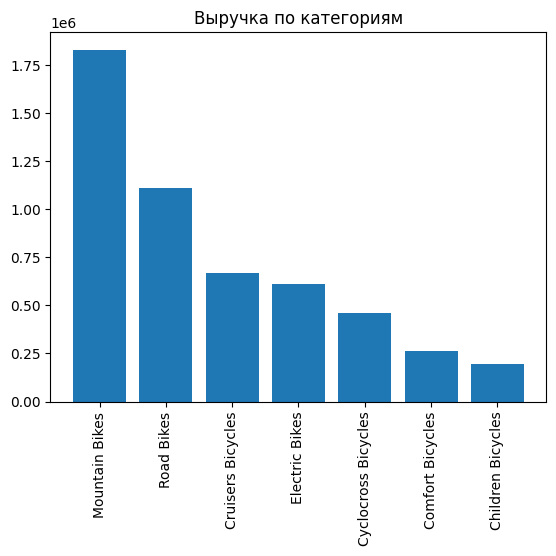

In [ ]:
plt.bar(revenue_by_category['category_name'], revenue_by_category['revenue'])
plt.xticks(rotation=90)
plt.title('Выручка по категориям')

Хиты продаж:

In [ ]:
top_items = orders_df_with_categories.groupby('product_name', as_index=False).agg(count=('item_id', 'count')).sort_values('count', ascending=False)
top_items.head(10)

,product_name,count
6,Electra Cruiser 1 (24-Inch) - 2016,193
72,Electra Townie Original 21D - 2016,193
81,Electra Townie Original 7D EQ - 2016,185
26,Electra Girl's Hawaii 1 (16-inch) - 2015/2016,180
136,Surly Ice Cream Truck Frameset - 2016,110
160,Trek Conduit+ - 2016,101
261,Trek Slash 8 27.5 - 2016,101
27,Electra Girl's Hawaii 1 (20-inch) - 2015/2016,100
79,Electra Townie Original 7D - 2015/2016,98
144,Surly Straggler - 2016,97


Худшие продажи:

In [ ]:
losers_items = orders_df_with_categories.groupby('product_name', as_index=False).agg(count=('item_id', 'count')).sort_values('count', ascending=True)
losers_items.head(10)

,product_name,count
249,Trek Precaliber 24 7-speed Girl's - 2018,1
248,Trek Precaliber 24 21-speed Girl's - 2018,1
52,Electra Tiger Shark 3i (20-inch) - Boys' - 2018,1
49,"Electra Superbolt 3i 20"" - 2018",1
48,"Electra Superbolt 1 20"" - 2018",1
43,Electra Straight 8 1 (20-inch) - Boy's - 2018,1
42,Electra Straight 8 1 (16-inch) - Boy's - 2018,1
40,Electra Soft Serve 1 (16-inch) - Girl's - 2018,1
222,Trek MT 201 - 2018,1
223,Trek Madone 9 Frameset - 2018,1


Проанализируем клиентов

## 👥 Раздел 4. Клиентская аналитика (Программа лояльности)

In [ ]:
client_statistic = orders_df.groupby('customer_id', as_index=False).agg(revenue=('discount_price', 'sum')).sort_values('revenue', ascending=False)
client_statistic.head(10)

,customer_id,revenue
5,6,22134.5598
93,94,21165.4861
0,1,20825.0694
15,16,18426.8007
74,75,18350.0397
65,66,17795.4276
9,10,17565.8222
72,73,17092.2366
53,54,16581.2534
92,93,16473.3869


In [ ]:
client_statistic_count = orders_df.groupby('customer_id', as_index=False).agg(count=('item_id', 'count')).sort_values('count', ascending=False)
client_statistic_count.head(10)

,customer_id,count
2,3,13
15,16,12
0,1,11
5,6,11
42,43,11
23,24,11
9,10,11
39,40,10
1,2,10
17,18,10


Для данных клиентов можно создать специальные условия, что бы поддерживать интерес к магазину